In [1]:
from mupt.graphs.generators import path_graph_from_sequence

from mupt.mupr.connection import Connector, AttachmentPoint
from mupt.mupr.primitives import RootPrimitive, CompositePrimitive, SimplePrimitive

from mupt.mupr.primitives.visualize import visualize_cross_section, visualize_hierarchy
from mupt.mupr.primitives.predicates import is_simple, is_subdominant

## Define Connectors
Essentially bond type: indicate orientation to guide the linker to a unique solution

In [2]:
conn_bb_fwd = Connector(AttachmentPoint({0}), AttachmentPoint({1})) # "forwards" along chain backbone
conn_bb_bwd = conn_bb_fwd.counterpart() # "backwards" along chain backbone

conn_sc_iwd = Connector(AttachmentPoint({2}), AttachmentPoint({3})) # "inwards" toward the backbone along a sidechain
conn_sc_owd = conn_sc_iwd.counterpart() # "outwards" away from the backbone along a sidechain

## Assemble sidechains

In [3]:
n_beads_sidechain_min : int = 1
n_beads_sidechain_max : int = 5
SIDECHAIN_LEN_KW : str = "sidechain_length"


# only SimplePrimitive instances can be directly assigned Connectors
lexicon_sidechain_units : dict[str, SimplePrimitive] = {
    "arm" : SimplePrimitive(connections=[conn_sc_iwd.copy(), conn_sc_owd.copy()]),
    "cap" : SimplePrimitive(connections=[conn_sc_iwd.copy()]),
}

In [4]:
lexicon_sidechains : dict[str, CompositePrimitive] = dict()
for sc_length in range(
    n_beads_sidechain_min,
    n_beads_sidechain_max + 1,
):
    sc_label : str = f"{sc_length}-unit sidechain"
    sc_graph = path_graph_from_sequence(["cap"] + (sc_length - 1)*['arm'])
    sc_prim = CompositePrimitive(label=sc_label, metadata={SIDECHAIN_LEN_KW : sc_length})
    sc_prim.populate_from_topology_and_lexicon(
        sc_graph,
        lexicon=lexicon_sidechain_units,
        set_label_from_lexicon=True,
    )
    # ax = visualize_cross_section(sc_prim, is_simple, use_shapes_for_pos=False)
    
    lexicon_sidechains[sc_label] = sc_prim

display(lexicon_sidechains)

{'1-unit sidechain': <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf0fe9850>,
 '2-unit sidechain': <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf10dca70>,
 '3-unit sidechain': <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf1085430>,
 '4-unit sidechain': <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf0ffd880>,
 '5-unit sidechain': <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf10190a0>}

## Mount sidechains onto backbone units 

In [5]:
lexicon_backbone : dict[str, SimplePrimitive] = {
    "head" : SimplePrimitive(connections=[conn_bb_fwd.copy()]),
    "mid_base" : SimplePrimitive(connections=[
        conn_bb_fwd.copy(),
        conn_sc_owd.copy(),
        conn_bb_bwd.copy(),
    ]),
    # mid variant definitions forthcoming
    "tail" : SimplePrimitive(connections=[conn_bb_bwd.copy()]),
}

mid_branched = SimplePrimitive(connections=[
    conn_bb_fwd.copy(),
    conn_sc_owd.copy(),
    conn_bb_bwd.copy(),
]),
for sc_name, sc_variant in lexicon_sidechains.items():
    # labels don't HAVE to be strings; only hashables
    mid_label = ("mid", sc_variant.metadata[SIDECHAIN_LEN_KW])
    
    mid_variant = CompositePrimitive(label=mid_label)
    mid_variant.populate_from_topology_and_lexicon(
        path_graph_from_sequence([sc_label, "mid_base"]),
        lexicon={
            sc_label : sc_variant,
            "mid_base" : lexicon_backbone["mid_base"].copy(),
        }
    )
    lexicon_backbone[mid_label] = mid_variant
    
display(lexicon_backbone)

{'head': <mupt.mupr.primitives.simple.simple.SimplePrimitive at 0x76ecf0fabd70>,
 'mid_base': <mupt.mupr.primitives.simple.simple.SimplePrimitive at 0x76ecf0fc4170>,
 'tail': <mupt.mupr.primitives.simple.simple.SimplePrimitive at 0x76ecf0fc4320>,
 ('mid',
  1): <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf0fc4830>,
 ('mid',
  2): <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf11a5d30>,
 ('mid',
  3): <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf0fc4980>,
 ('mid',
  4): <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ecf0fc57f0>,
 ('mid',
  5): <mupt.mupr.primitives.composite.CompositePrimitive at 0x76ed21d164b0>}

<Axes: >

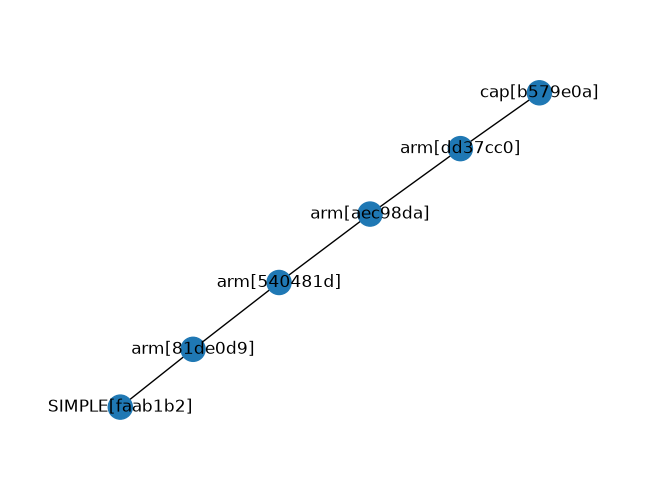

In [6]:
visualize_cross_section(lexicon_backbone[("mid", 5)], is_simple, use_shapes_for_pos=False)

## Assemble chain(s) and create system

In [7]:
from random import randrange

def CG_bead_chain_branched(chain_len : int, name : str="chain") -> CompositePrimitive:
    """
    Build a linear coarse grained polymer chain with sidechain lengths
    uniformly distributed among the pre-defined range of sidechain sizes
    """
    assert chain_len >= 2
    
    mid_unit_labels : list[tuple[str, int]] = []
    for _ in range(chain_len - 2):
        sc_len : int = randrange(n_beads_sidechain_min, n_beads_sidechain_max + 1)
        mid_unit_labels.append(("mid", sc_len))
        
    chain_prim = CompositePrimitive(label=f"CG_{chain_len}-mer")
    chain_prim.populate_from_topology_and_lexicon(
        path_graph_from_sequence(["head"] + mid_unit_labels + ["tail"]),
        lexicon=lexicon_backbone,
        set_label_from_lexicon=True,
    )
    
    return chain_prim

### Probe at different levels of resolution

In [8]:
single_chain = CG_bead_chain_branched(20)

#### One-bead per backbone unit

<Axes: >

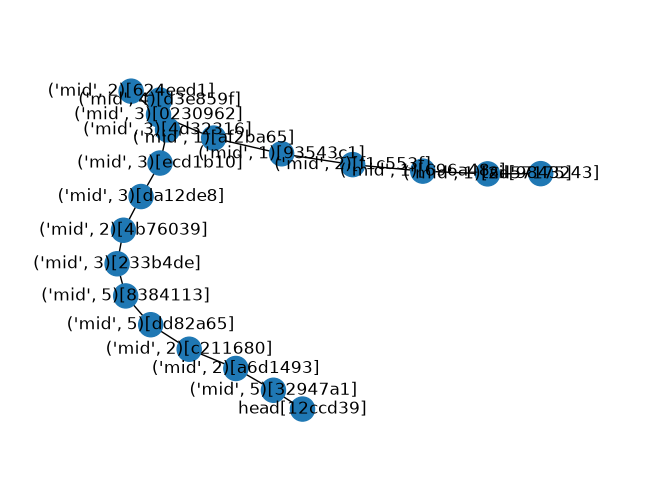

In [9]:
visualize_cross_section(
    single_chain,
    is_subdominant,
    use_shapes_for_pos=False,
)

#### Two beads per unit (backbone + sidechain)

<Axes: >

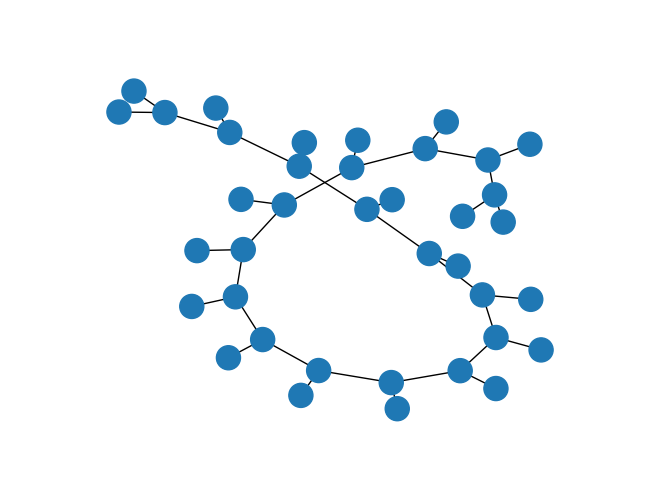

In [10]:
visualize_cross_section(
    single_chain,
    lambda prim : all(is_simple(child) for child in prim.children),
    use_shapes_for_pos=False,
    with_labels=False,
)

#### Many beads per sidechain 

<Axes: >

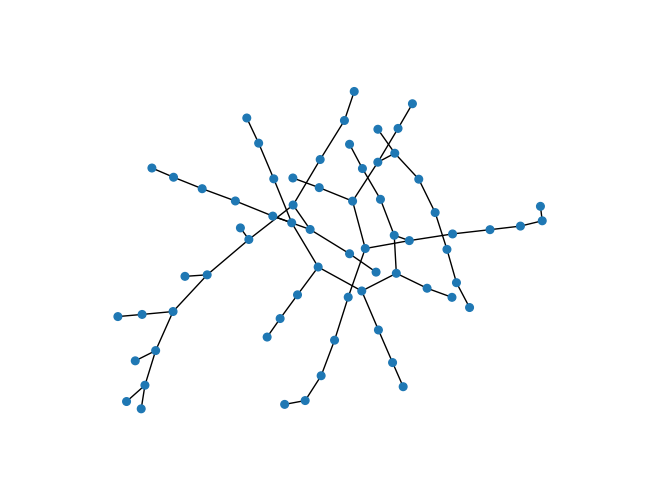

In [11]:
visualize_cross_section(
    single_chain,
    is_simple,
    use_shapes_for_pos=False,
    with_labels=False,
    node_size=30
)

## Export system to mBuild for FlowerMD

In [12]:
n_chains : int = 5
DOP : int = 20

system = RootPrimitive(label="system")
for i in range(n_chains):
    chain = CG_bead_chain_branched(20, name=f"{DOP}-mer_{i}")
    system.attach_child(chain)

In [ ]:
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

compound = primitive_to_mbuild(system, is_simple, preserve_intermediates=True) # or any of the above resolutions
print(compound, set(str(compound.pos) for child in compound.children))
print(f"{len(compound.children)} distinct chains present")

In [ ]:
compound.print_hierarchy()